# Problem 3: Metropolis–Hastings with a uniform target

Continue Problem 2 with a density uniform on $3<x<7$ and zero elsewhere. We keep the Gaussian random-walk proposal with variance 1, seed 42, and 50,000 transitions. Only NumPy and Matplotlib are needed.

## Target and initialization

The normalized target is
$$p(x)=\begin{cases}1/4,&3<x<7,\\0,&\text{otherwise}.\end{cases}$$
Its mean is $(3+7)/2=5$ and variance is $(7-3)^2/12=4/3$.

**Change the initial state from $x=0$ to $x=5$.** Any point strictly inside $(3,7)$ would work. In Problem 2 the Gaussian density was positive at every finite $x$. Here $p(0)=0$, so the usual acceptance ratio $p(x')/p(x)$ has a zero denominator at the old starting point. If the proposal also lies outside the support, this gives the undefined ratio $0/0$. In log space this becomes $-\infty-(-\infty)$, which is undefined as well.

Starting at positive target density keeps the acceptance calculation well defined. An implementation could explicitly handle an invalid initial state, but this simple sampler avoids that case by starting inside the support.

## Acceptance at the boundaries

As in Problem 2, propose $x'\sim\mathcal N(x,1)$. Symmetry cancels the proposal densities:
$$\alpha(x,x')=\min\left(1,\frac{p(x')}{p(x)}\right).$$
From a valid current state, every proposal inside $(3,7)$ is accepted because the density ratio is 1. Every proposal outside is rejected because the ratio is 0. The unnormalized log density is therefore
$$\ell(x)=\begin{cases}0,&3<x<7,\\-\infty,&\text{otherwise}.\end{cases}$$
The constant $\log(1/4)$ cancels, so we can use 0 inside. We keep the same log acceptance test and sampler loop as Problem 2. In particular, proposals are neither clipped nor redrawn at the boundaries; a rejection stores the current state again.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def log_p(x):
    return 0.0 if 3 < x < 7 else -np.inf

rng = np.random.default_rng(42)
x = 5.0
samples = np.empty(50_000)
accepted = 0
for i in range(len(samples)):
    proposal = rng.normal(x, 1.0)
    if np.log(rng.random()) < min(0.0, log_p(proposal) - log_p(x)):
        x = proposal
        accepted += 1
    samples[i] = x

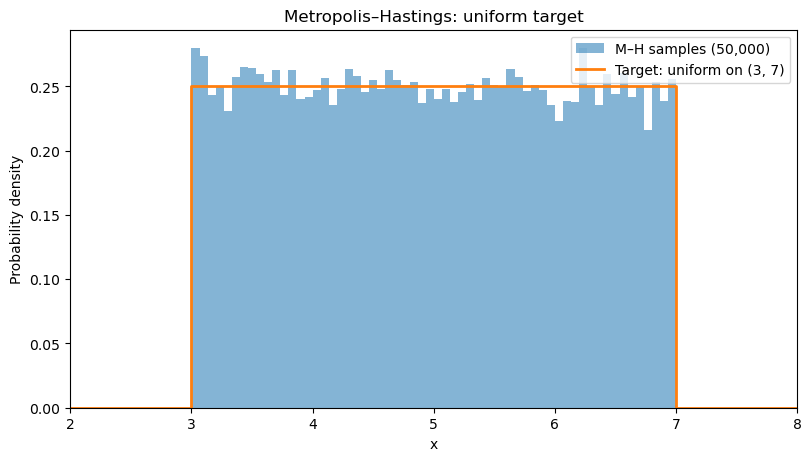

Sample mean: 4.9834 (target: 5)
Sample variance: 1.3394 (target: 1.3333)
Acceptance fraction: 0.800


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(samples, bins=60, range=(3, 7), density=True, alpha=0.55,
        label="M–H samples (50,000)")
ax.plot([2, 3, 3, 7, 7, 8], [0, 0, 0.25, 0.25, 0, 0],
        color="tab:orange", linewidth=2, label="Target: uniform on (3, 7)")
ax.set(xlabel="x", ylabel="Probability density", xlim=(2, 8),
       title="Metropolis–Hastings: uniform target")
ax.legend()
plt.show()
print(f"Sample mean: {samples.mean():.4f} (target: 5)")
print(f"Sample variance: {samples.var():.4f} (target: {4/3:.4f})")
print(f"Acceptance fraction: {accepted / len(samples):.3f}")

## What can we conclude?

The histogram is approximately flat at density $1/4$ between 3 and 7, with no samples outside. The vertical lines in the analytic overlay indicate the density jumps; the endpoints themselves have zero probability in a continuous distribution.

We store all 50,000 states after transitions, including repeated states on rejection, and discard no burn-in. Although the initial state is at the target mean, a fixed starting point is not itself a draw from the stationary distribution. Neighboring states remain correlated, so the histogram and sample moments fluctuate.

The essential initialization change is to start **where the target density is positive**. This lets the same Metropolis–Hastings loop handle a density with hard boundaries.